# Day 20 — Foundation Mini Project
## Retail Sales & Customer Analytics
**Dataset:** original Day 5 retail orders, 30 records, October 2026.

**Important:** This small single-month dataset is appropriate for demonstrating an analytics workflow, not for dependable forecasting. Sales equals Quantity × Unit_Price; the ML section illustrates a pipeline, not independent discovery or future demand forecasting.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style="whitegrid")
root = Path.cwd()
if not (root / "data" / "retail_sales.csv").exists():
    root = root.parent
assert (root / "data" / "retail_sales.csv").exists(), "Open the project root folder in VS Code."
(root / "charts").mkdir(exist_ok=True)
print("Project directory:", root)

Project directory: /mnt/data/Day20_Foundation_Mini_Project


## 1. Load and understand data

In [2]:
df = pd.read_csv(root / "data" / "retail_sales.csv", parse_dates=["Order_Date"])
print("Rows and columns:", df.shape)
print("Missing values:\n", df.isna().sum())
display(df.head())

Rows and columns: (30, 10)
Missing values:
 Order_ID           0
Order_Date         0
Customer_Name      0
City               0
Category           0
Product            0
Quantity           0
Unit_Price         0
Sales              0
Customer_Rating    3
dtype: int64


,Order_ID,Order_Date,Customer_Name,City,Category,Product,Quantity,Unit_Price,Sales,Customer_Rating
0,ORD001,2026-10-02,Rahul,Mumbai,Clothing,T-Shirt,2,650,1300,5.0
1,ORD002,2026-10-03,Neha,Nagpur,Grocery,Rice,3,320,960,3.0
2,ORD003,2026-10-04,Vikram,Nashik,Home,Lamp,4,1100,4400,4.0
3,ORD004,2026-10-05,Priya,Pune,Electronics,Headphones,5,1500,7500,5.0
4,ORD005,2026-10-06,Arjun,Pune,Clothing,T-Shirt,1,650,650,4.0


## 2. Clean data and validate calculated sales

In [3]:
clean = df.drop_duplicates(subset="Order_ID").copy()
clean["Customer_Rating"] = clean["Customer_Rating"].fillna(clean["Customer_Rating"].median())
clean["Order_Month"] = clean["Order_Date"].dt.to_period("M").astype(str)
print("Sales mismatch count:", (clean["Sales"] != clean["Quantity"] * clean["Unit_Price"]).sum())
print("Missing after cleaning:", clean.isna().sum().sum())
clean.to_csv(root / "data" / "retail_sales_cleaned.csv", index=False)

Sales mismatch count: 0
Missing after cleaning: 0


## 3. Business KPIs and EDA

In [4]:
kpis = pd.Series({"Orders":len(clean),"Revenue_INR":clean.Sales.sum(),"Units":clean.Quantity.sum(),"Unique_Customers":clean.Customer_Name.nunique(),"Average_Order_Value_INR":round(clean.Sales.mean(),2)})
print(kpis.to_string())
category = clean.groupby("Category", as_index=False)["Sales"].sum().sort_values("Sales",ascending=False)
city = clean.groupby("City", as_index=False)["Sales"].sum().sort_values("Sales",ascending=False)
display(category); display(city)

Orders                        30.0
Revenue_INR                81870.0
Units                         90.0
Unique_Customers               6.0
Average_Order_Value_INR     2729.0


,Category,Sales
1,Electronics,36000
3,Home,24200
0,Clothing,14950
2,Grocery,6720


,City,Sales
3,Pune,33140
2,Nashik,24680
1,Nagpur,14970
0,Mumbai,9080


## 4. Matplotlib + Seaborn charts

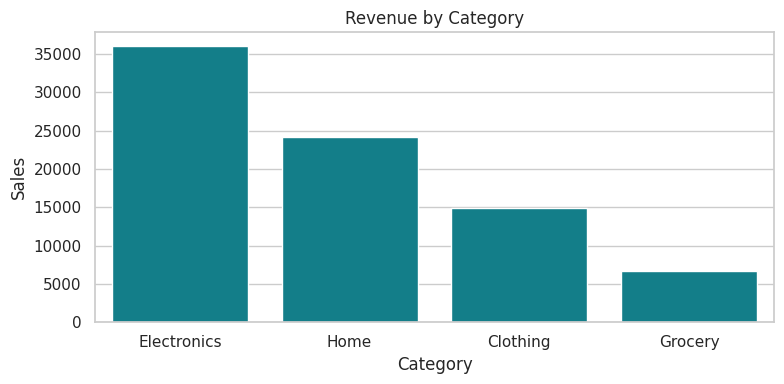

In [5]:
fig,ax=plt.subplots(figsize=(8,4)); sns.barplot(data=category,x="Category",y="Sales",ax=ax,color="#008e9c"); ax.set_title("Revenue by Category"); plt.tight_layout();plt.savefig(root/"charts"/"revenue_by_category.png",dpi=150);plt.show()

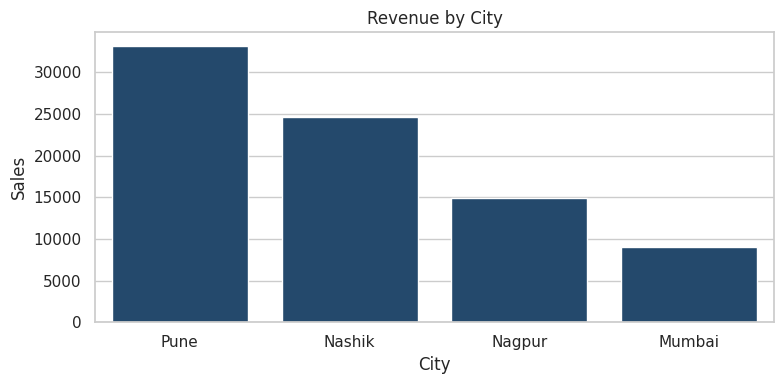

In [6]:
fig,ax=plt.subplots(figsize=(8,4));sns.barplot(data=city,x="City",y="Sales",ax=ax,color="#184a78");ax.set_title("Revenue by City");plt.tight_layout();plt.savefig(root/"charts"/"revenue_by_city.png",dpi=150);plt.show()

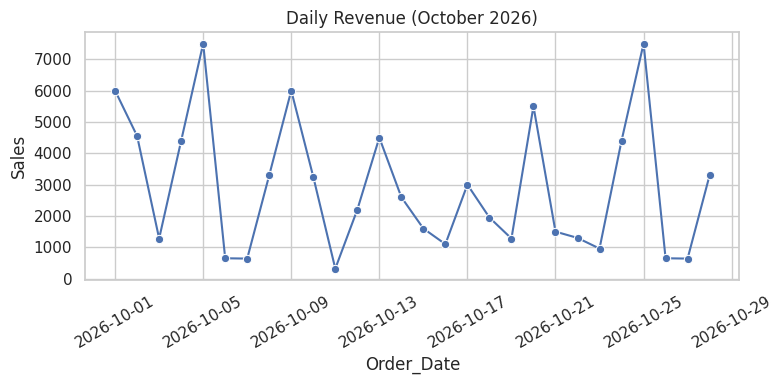

In [7]:
daily=clean.groupby("Order_Date",as_index=False).Sales.sum();fig,ax=plt.subplots(figsize=(8,4));sns.lineplot(data=daily,x="Order_Date",y="Sales",marker="o",ax=ax);ax.set_title("Daily Revenue (October 2026)");plt.xticks(rotation=30);plt.tight_layout();plt.savefig(root/"charts"/"daily_revenue.png",dpi=150);plt.show()

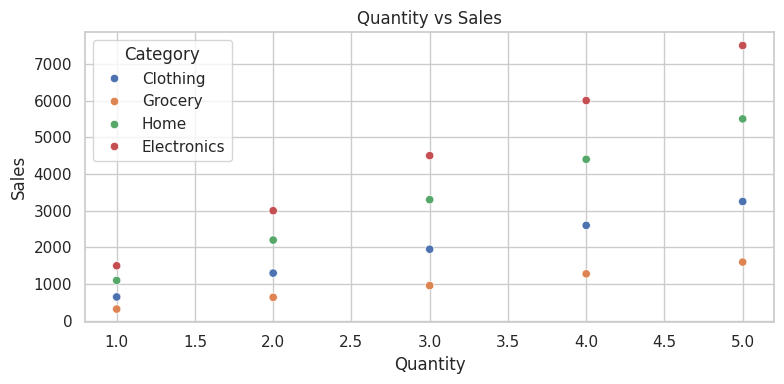

In [8]:
fig,ax=plt.subplots(figsize=(8,4));sns.scatterplot(data=clean,x="Quantity",y="Sales",hue="Category",ax=ax);ax.set_title("Quantity vs Sales");plt.tight_layout();plt.savefig(root/"charts"/"quantity_vs_sales.png",dpi=150);plt.show()

## 5. Basic ML: order sales estimation (demonstration only)
Target: `Sales`. Inputs: Quantity, Unit_Price, City, Category. This target is exactly Quantity × Unit_Price, so the task is **not** an independent sales forecast. Only 9 test rows; performance is unstable. Do not use this model for business decisions.

In [9]:
X=clean[["Quantity","Unit_Price","City","Category"]];y=clean["Sales"]
pre=ColumnTransformer([("num",SimpleImputer(strategy="median"),["Quantity","Unit_Price"]),( "cat",Pipeline([("fill",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),["City","Category"])])
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.30,random_state=42)
rows=[]
for name,est in [("Linear Regression",LinearRegression()),("Decision Tree",DecisionTreeRegressor(max_depth=4,random_state=42))]:
    pipe=Pipeline([("preprocess",pre),("model",est)])
    pipe.fit(X_train,y_train)
    p=pipe.predict(X_test)
    rows.append({"Model":name,"MAE":round(mean_absolute_error(y_test,p),2),"RMSE":round(np.sqrt(mean_squared_error(y_test,p)),2),"R2":round(r2_score(y_test,p),4)})
comparison=pd.DataFrame(rows);display(comparison)
comparison.to_csv(root/"data"/"model_comparison.csv",index=False)

,Model,MAE,RMSE,R2
0,Linear Regression,777.73,833.41,0.8614
1,Decision Tree,1518.52,2325.24,-0.0785


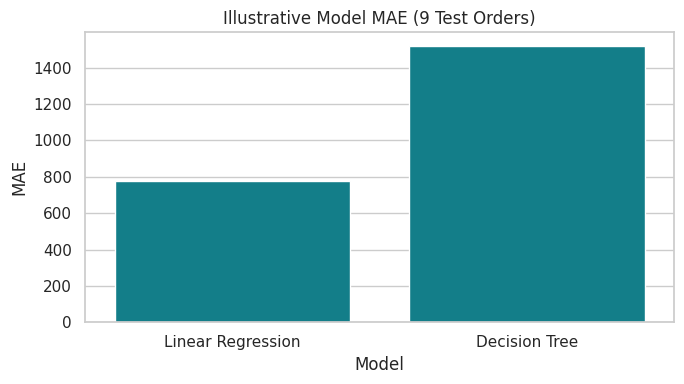

In [10]:
fig,ax=plt.subplots(figsize=(7,4));sns.barplot(data=comparison,x="Model",y="MAE",ax=ax,color="#008e9c");ax.set_title("Illustrative Model MAE (9 Test Orders)");plt.tight_layout();plt.savefig(root/"charts"/"model_comparison.png",dpi=150);plt.show()

## 6. Business insights and next steps
- Electronics contributes the largest revenue share in this sample.
- Pune leads city revenue in the observed orders.
- There are only 30 orders from one month; avoid generalizing seasonal trends.
- Profit cannot be calculated because costs are absent.
- Customer ratings had three missing entries; median imputation is for demonstration only.
- For future ML, collect more months, marketing, cost, and customer behavior data.

**SQL:** See `sql/Day20_SQL_Analysis.sql`. **Power BI:** See `powerbi/PowerBI_Dashboard_Build_Guide.md`.